Loading previous_application data...
Loaded 1,670,214 past loan applications from 338,857 unique clients.


Previous application: all column names and their data types
str        16
float64    15
int64       6
Name: count, dtype: int64

--- NAME_CONTRACT_TYPE (4 unique categories) ---
NAME_CONTRACT_TYPE
Cash loans         0.447579
Consumer loans     0.436561
Revolving loans    0.115652
XNA                0.000207
Name: proportion, dtype: float64

--- WEEKDAY_APPR_PROCESS_START (7 unique categories) ---
WEEKDAY_APPR_PROCESS_START
TUESDAY      0.152746
WEDNESDAY    0.152681
MONDAY       0.151811
FRIDAY       0.150908
Name: proportion, dtype: float64

--- FLAG_LAST_APPL_PER_CONTRACT (2 unique categories) ---
FLAG_LAST_APPL_PER_CONTRACT
Y    0.994926
N    0.005074
Name: proportion, dtype: float64

--- NAME_CASH_LOAN_PURPOSE (25 unique categories) ---
NAME_CASH_LOAN_PURPOSE
XAP        0.552421
XNA        0.405887
Repairs    0.014229
Other      0.009345
Name: proportion, dtype: float64

--- 

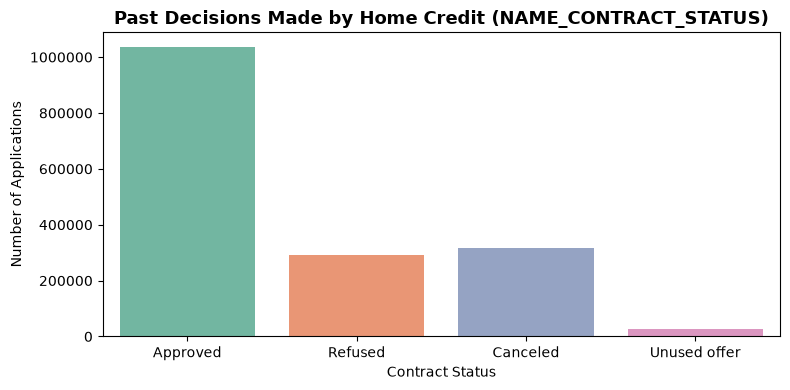


Calculating client-level refusal rates...


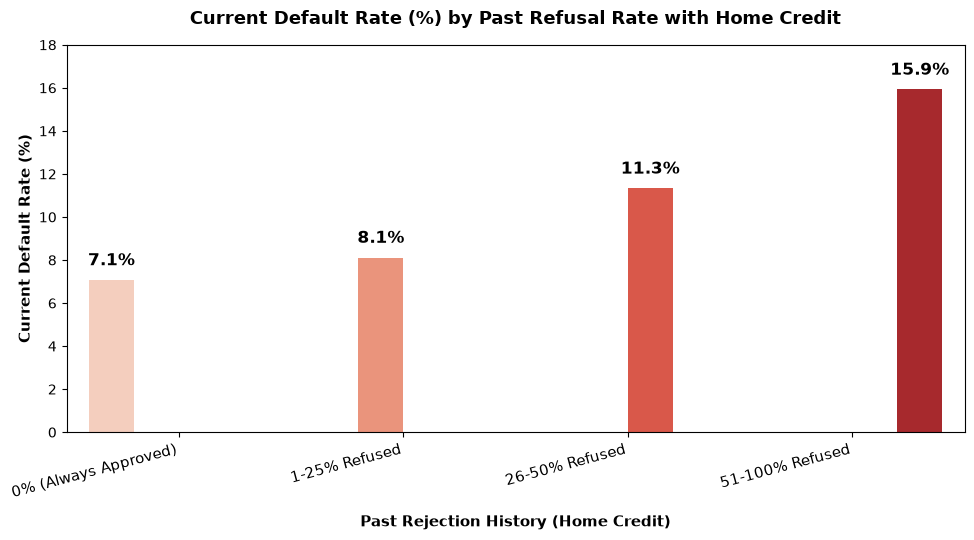

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Smart Path Finder
data_dir = Path("data") if Path("data").exists() else (Path("../data") if Path("../data").exists() else Path("../../data"))

print("Loading previous_application data...")
prev = pd.read_csv(data_dir / "previous_application.csv")
app = pd.read_csv(data_dir / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])



print(f"Loaded {len(prev):,} past loan applications from {prev['SK_ID_CURR'].nunique():,} unique clients.")

# 1. all column names and their data types
print("\n\nPrevious application: all column names and their data types")
print(prev.dtypes.value_counts())

# 2. Check which categorical columns have interesting values
for col in prev.select_dtypes(include=['object', 'str']).columns:
    print(f"\n--- {col} ({prev[col].nunique()} unique categories) ---")
    print(prev[col].value_counts(normalize=True).head(4))

# 1. Look at Past Contract Decisions (Approved vs Refused)
plt.figure(figsize=(8, 4))
sns.countplot(
    data=prev,
    x="NAME_CONTRACT_STATUS",
    hue="NAME_CONTRACT_STATUS",
    palette="Set2",
    legend=False
)
plt.title("Past Decisions Made by Home Credit (NAME_CONTRACT_STATUS)", fontsize=13, fontweight="bold")
plt.xlabel("Contract Status")
plt.ylabel("Number of Applications")
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()


# 2. Aggregate Refusal Rates per Applicant
print("\nCalculating client-level refusal rates...")
prev_agg = prev.groupby("SK_ID_CURR").agg(
    TOTAL_PREV_APPS=("SK_ID_PREV", "count"),
).reset_index()

refused = prev[prev["NAME_CONTRACT_STATUS"] == "Refused"].groupby("SK_ID_CURR")["SK_ID_PREV"].count().rename("REFUSED_COUNT")
prev_agg = prev_agg.merge(refused, on="SK_ID_CURR", how="left").fillna(0)
prev_agg["REFUSAL_RATE"] = prev_agg["REFUSED_COUNT"] / prev_agg["TOTAL_PREV_APPS"]

# Merge with TARGET
merged_prev = app.merge(prev_agg, on="SK_ID_CURR", how="inner")


# 3. Visualizing the Golden Insight: Does Past Refusal Predict Future Default?
merged_prev["REFUSAL_BIN"] = pd.cut(
    merged_prev["REFUSAL_RATE"],
    bins=[-0.1, 0.0, 0.25, 0.50, 1.0],
    labels=["0% (Always Approved)", "1-25% Refused", "26-50% Refused", "51-100% Refused"]
)
default_by_refusal = merged_prev.groupby("REFUSAL_BIN", observed=False)["TARGET"].mean() * 100

# Past Refusal Rate vs Current Default Rate
plt.figure(figsize=(10, 5.5))

ax = sns.barplot(
    x=default_by_refusal.index,
    y=default_by_refusal.values,
    hue=default_by_refusal.index,
    palette="Reds",
    legend=False
)

plt.title("Current Default Rate (%) by Past Refusal Rate with Home Credit", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Past Rejection History (Home Credit)", fontsize=11, fontweight="bold", labelpad=10)
plt.ylabel("Current Default Rate (%)", fontsize=11, fontweight="bold")

plt.ylim(0, 18)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.1f}%",
        xy=(p.get_x() + p.get_width() / 2, height + 0.5),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.xticks(rotation=15, ha="right", fontsize=11)
plt.tight_layout()
plt.show()



